# Notebook 06 · Demostración interactiva de inferencia MRI de rodilla

**Objetivo:** mostrar en vivo la predicción multietiqueta de EfficientNet-B0 (sagital 2.5D + Focal) usando los 39 estudios **GOLD DEV**. El modelo se carga una sola vez y **no se entrena**.

**Qué demuestra:** las tres vistas MRI, probabilidades de 12 hallazgos, umbral fijo **0.54**, comparación con etiquetas GOLD y aciertos/errores por estudio. Las etiquetas desconocidas (`-1`) se excluyen de la comparación. No utiliza HOLDOUT.

**Advertencia metodológica:** los casos GOLD DEV fueron usados para seleccionar el umbral; los ejemplos son ilustrativos, no una nueva medición independiente del rendimiento ni un diagnóstico clínico. Las métricas finales están en el Notebook 05.

**Uso:** ejecutar celdas de preparación una vez; luego cambiar de estudio usando el selector de la última celda. `ipywidgets` es opcional; se ofrece alternativa manual.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.models import efficientnet_b0

actual = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [actual, *actual.parents] if (p / "config" / "config.yaml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró config/config.yaml. Abre el notebook desde el repositorio.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.config import load_config, get_data_root

config = load_config()
DATA_ROOT = get_data_root(config)
IMAGES_PATH = DATA_ROOT / "processed" / "images_2_5d_uint8.npy"
METADATA_PATH = DATA_ROOT / "processed" / "metadata_2_5d.csv"
CHECKPOINT_PATH = DATA_ROOT / "checkpoint" / "best_ablacion_focal.pth"
for archivo in [IMAGES_PATH, METADATA_PATH, CHECKPOINT_PATH]:
    if not archivo.is_file():
        raise FileNotFoundError(f"Archivo requerido ausente: {archivo}")

LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
UMBRAL = 0.54
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Raíz:", PROJECT_ROOT, " | Datos:", DATA_ROOT, " | Dispositivo:", DEVICE)

Raíz: C:\Users\PC\Documents\knee-mri-weak-supervision  | Datos: C:\Users\PC\Documents\RSNA_Knee  | Dispositivo: cpu


## 1 · Cargar los estudios GOLD DEV (sin DICOM ni reconstrucción)

In [2]:
images = np.load(IMAGES_PATH, mmap_mode="r")
metadata = pd.read_csv(METADATA_PATH, dtype={"StudyInstanceUID": str, "SeriesInstanceUID": str})
dev = metadata.loc[metadata["Split"] == "validation"].reset_index(drop=True).copy()
assert images.shape == (546, 3, 3, 224, 224), images.shape
assert images.dtype == np.uint8
assert len(dev) == 39
assert all(0 <= int(k) < len(images) for k in dev["ImageIndex"])
assert dev["StudyInstanceUID"].is_unique
assert set(LABELS).issubset(dev.columns)
print("✅ Estudios GOLD DEV:", len(dev), "| Imágenes:", images.shape, "| Etiquetas:", len(LABELS))

✅ Estudios GOLD DEV: 39 | Imágenes: (546, 3, 3, 224, 224) | Etiquetas: 12


## 2 · Arquitectura original y checkpoint Focal sagital

In [3]:
class EfficientNet2_5D(nn.Module):
    """Misma arquitectura y normalización de Notebook 05."""
    def __init__(self, num_classes=12, dropout=0.3, usar_imagenet=False):
        super().__init__()
        # weights=None: el checkpoint carga los pesos originales y no requiere descarga.
        self.backbone = efficientnet_b0(weights=None)
        self.feature_dim = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.feature_dim, num_classes))
        mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(1, 1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(1, 1, 3, 1, 1)
        self.register_buffer("imagenet_mean", mean)
        self.register_buffer("imagenet_std", std)

    def forward(self, x):
        B, V, C, H, W = x.shape
        x = (x - self.imagenet_mean) / self.imagenet_std
        x = x.reshape(B * V, C, H, W)
        features = self.backbone(x).reshape(B, V, self.feature_dim).mean(dim=1)
        return self.classifier(features)

modelo = EfficientNet2_5D(num_classes=len(LABELS), usar_imagenet=False).to(DEVICE)
modelo.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
modelo.eval()
print("✅ Checkpoint cargado:", CHECKPOINT_PATH)
print("Modo entrenamiento:", modelo.training, "(debe ser False)")

✅ Checkpoint cargado: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_focal.pth
Modo entrenamiento: False (debe ser False)


## 3 · Motor de inferencia: una carga del modelo, múltiples casos

Cada caso se procesa en memoria, sin escribir datos ni modificar pesos. La función cachea probabilidades para que al volver a un caso la demostración sea inmediata.

In [4]:
from IPython.display import display, clear_output

_cache = {}

def inferir_caso(caso_dev):
    caso_dev = int(caso_dev)
    if not 0 <= caso_dev < len(dev):
        raise ValueError(f"CASO_DEV debe estar entre 0 y {len(dev)-1}")
    if caso_dev not in _cache:
        fila = dev.iloc[caso_dev]
        indice = int(fila["ImageIndex"])
        volumen = np.array(images[indice], copy=True)
        assert volumen.shape == (3, 3, 224, 224)
        x = torch.from_numpy(volumen.astype(np.float32) / 255.0).unsqueeze(0).to(DEVICE)
        with torch.inference_mode():
            probabilidades = torch.sigmoid(modelo(x)).cpu().numpy()[0]
        assert probabilidades.shape == (len(LABELS),)
        assert np.isfinite(probabilidades).all()
        _cache[caso_dev] = (volumen, probabilidades)
    return _cache[caso_dev]


def mostrar_caso(caso_dev=0):
    caso_dev = int(caso_dev)
    fila = dev.iloc[caso_dev]
    volumen, probabilidades = inferir_caso(caso_dev)
    gold = fila[LABELS].to_numpy(dtype=float)
    pred = (probabilidades >= UMBRAL).astype(int)
    estados = np.where(gold == -1, "No evaluable",
             np.where((pred == 1) & (gold == 1), "Verdadero positivo",
             np.where((pred == 0) & (gold == 0), "Verdadero negativo",
             np.where((pred == 1) & (gold == 0), "Falso positivo", "Falso negativo"))))
    tabla = pd.DataFrame({
        "Hallazgo": LABELS,
        "Probabilidad": probabilidades,
        "Predicción": pred,
        "GOLD": gold,
        "Resultado": estados
    })
    validos = gold != -1
    n_correctos = int(((pred == gold) & validos).sum())
    print(f"GOLD DEV {caso_dev:02d} | ImageIndex {int(fila['ImageIndex'])} | Estudio {fila['StudyInstanceUID']}")
    print(f"Umbral fijo: {UMBRAL:.2f} | {n_correctos}/{int(validos.sum())} etiquetas evaluables correctas")
    print(f"VP: {(estados == 'Verdadero positivo').sum()} | VN: {(estados == 'Verdadero negativo').sum()} | FP: {(estados == 'Falso positivo').sum()} | FN: {(estados == 'Falso negativo').sum()} | Sin etiqueta: {(~validos).sum()}")

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for j, ax in enumerate(axes):
        ax.imshow(volumen[j, 1], cmap="gray", vmin=0, vmax=255)
        ax.set_title(["Corte 30 %", "Corte 50 %", "Corte 70 %"][j]); ax.axis("off")
    fig.suptitle(f"MRI sagital 2.5D | GOLD DEV {caso_dev:02d}")
    plt.tight_layout(); plt.show()

    orden = np.argsort(probabilidades)
    colores = ["#17836f" if pred[i] == 1 else "#9da4ae" for i in orden]
    fig, ax = plt.subplots(figsize=(10, 5.7))
    ax.barh(np.asarray(LABELS)[orden], probabilidades[orden], color=colores)
    ax.axvline(UMBRAL, color="firebrick", linestyle="--", linewidth=1.5,
               label=f"Umbral seleccionado en DEV = {UMBRAL:.2f}")
    ax.set_xlim(0, 1.08); ax.set_xlabel("Salida sigmoide del modelo (0–1)")
    ax.set_title("Predicciones para las 12 patologías")
    for k, idx in enumerate(orden):
        ax.text(float(probabilidades[idx]) + 0.012, k, f"{probabilidades[idx]:.3f}", va="center", fontsize=9)
    ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
    display(tabla.style.format({"Probabilidad": "{:.4f}", "GOLD": "{:.0f}"})
            .apply(lambda col: ["background-color: #d9f3e7" if v in ("Verdadero positivo", "Verdadero negativo")
                                else "background-color: #ffe8dc" if v in ("Falso positivo", "Falso negativo")
                                else "" for v in col], subset=["Resultado"]))
    print("Interpretación académica: las predicciones no equivalen a un diagnóstico clínico.")
    return tabla

print("✅ Motor de inferencia listo. Modelo en evaluación:", not modelo.training)


✅ Motor de inferencia listo. Modelo en evaluación: True


## 4 · Verificación de integridad del experimento

Esta comprobación verifica que los identificadores y etiquetas del estudio sean coherentes, que el modelo siga en evaluación y que la inferencia sea determinista para un mismo caso. **No equivale todavía a una comparación externa con el CSV de probabilidades del Notebook 05**, que habría que cargar por UID si se exporta.

In [5]:
assert not modelo.training
assert dev["StudyInstanceUID"].is_unique
assert dev["ImageIndex"].is_unique
assert not dev[LABELS].isna().any().any()
assert np.isin(dev[LABELS].to_numpy(), [-1, 0, 1]).all()
volumen_0, p0 = inferir_caso(0)
_, p0_repetido = inferir_caso(0)
assert np.array_equal(p0, p0_repetido)
assert p0.min() >= 0 and p0.max() <= 1
print("✅ Identificadores, GOLD, umbral y predicciones en memoria validados")
print("Caso 0 | rango de probabilidades:", round(float(p0.min()), 5), "a", round(float(p0.max()), 5))
print("NOTA: se reutiliza el checkpoint original, no se ejecuta entrenamiento ni HOLDOUT.")


✅ Identificadores, GOLD, umbral y predicciones en memoria validados
Caso 0 | rango de probabilidades: 0.03633 a 0.91611
NOTA: se reutiliza el checkpoint original, no se ejecuta entrenamiento ni HOLDOUT.


## 5 · Demostración en vivo

**Opción A (recomendada):** usa el menú desplegable y el botón **Analizar caso**. Primero prepara uno o dos ejemplos y verifica que entiendes sus aciertos y errores.

**Opción B:** si `ipywidgets` no está disponible, ejecuta la celda manual del final cambiando `CASO_DEV`.

In [6]:
try:
    import ipywidgets as widgets
    selector = widgets.Dropdown(
        options=[(f"GOLD DEV {i:02d} | ImageIndex {int(dev.iloc[i]['ImageIndex'])}", i) for i in range(len(dev))],
        value=0, description="Estudio:", layout=widgets.Layout(width="390px")
    )
    boton = widgets.Button(description="Analizar caso", button_style="primary", icon="search")
    salida = widgets.Output()

    def al_pulsar(_):
        boton.disabled = True
        try:
            with salida:
                clear_output(wait=True)
                mostrar_caso(selector.value)
        finally:
            boton.disabled = False

    boton.on_click(al_pulsar)
    display(widgets.VBox([widgets.HBox([selector, boton]), salida]))
    print("✅ Selector listo. Selecciona un caso y pulsa «Analizar caso».")
except ImportError:
    print("ipywidgets no está instalado. Usa la celda manual siguiente.")
    print("Para instalar: python -m pip install ipywidgets")


✅ Selector listo. Selecciona un caso y pulsa «Analizar caso».


GOLD DEV 00 | ImageIndex 490 | Estudio 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Umbral fijo: 0.54 | 8/12 etiquetas evaluables correctas
VP: 2 | VN: 6 | FP: 4 | FN: 0 | Sin etiqueta: 0


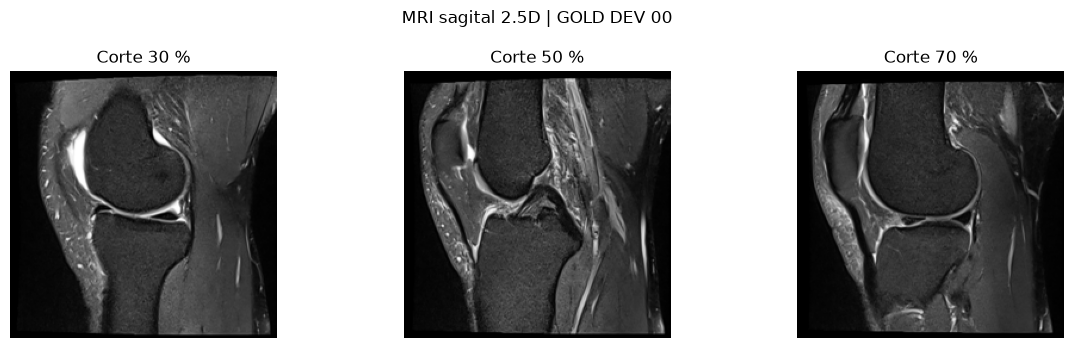

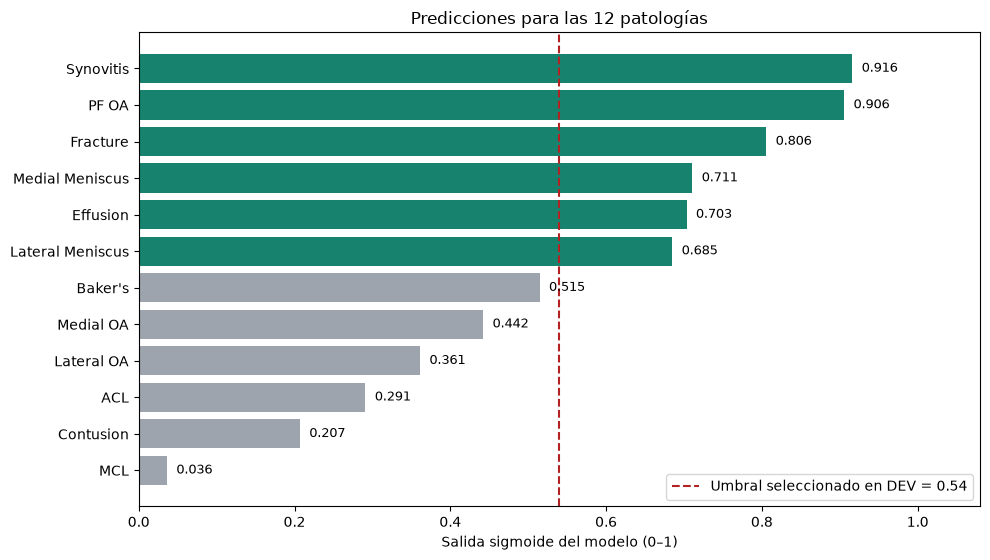

,Hallazgo,Probabilidad,Predicción,GOLD,Resultado
0,ACL,0.2911,0,0,Verdadero negativo
1,MCL,0.0363,0,0,Verdadero negativo
2,Medial Meniscus,0.7108,1,0,Falso positivo
3,Lateral Meniscus,0.6850,1,0,Falso positivo
4,Medial OA,0.4422,0,0,Verdadero negativo
5,Lateral OA,0.3612,0,0,Verdadero negativo
6,PF OA,0.9056,1,1,Verdadero positivo
7,Effusion,0.7033,1,1,Verdadero positivo
8,Synovitis,0.9161,1,0,Falso positivo
9,Baker's,0.5147,0,0,Verdadero negativo


Interpretación académica: las predicciones no equivalen a un diagnóstico clínico.


In [7]:
# Alternativa manual, útil incluso sin ipywidgets.
# Cambia únicamente CASO_DEV y ejecuta ESTA celda.
CASO_DEV = 0
_ = mostrar_caso(CASO_DEV)
